# PRCP-1018 · Bike Sharing Demand — Analysis & Prediction

**Dataset:** Capital Bikeshare (Washington D.C.), daily & hourly rentals, 2011-01-01 → 2012-12-31 (UCI Bike Sharing Dataset)

**Deliverables in this notebook**

| # | Deliverable | Section |
|---|-------------|---------|
| 1 | Complete data analysis report (Task 1) | Sections 2 – 5 |
| 2 | Prediction of daily rental count from environmental & seasonal settings (Task 2) | Sections 6 – 8 |
| 3 | Model comparison report + production recommendation | Section 9 |
| 4 | Report on challenges faced, techniques used and reasoning | Section 10 |

**Approach in one paragraph.** `day.csv` (731 days) is the modelling dataset because the task is *daily* count prediction; `hour.csv` (17,379 rows) is used only for extra intraday EDA. The target is `cnt`. `casual` and `registered` are excluded from the features because they sum exactly to `cnt` (target leakage). Eleven regression models are compared with 5-fold cross-validation, tuned with randomized search, and finally judged on two held-out views: a random 80/20 split and a chronological split (train on the past, predict the future).

> **How to run:** unzip `PRCP-1018-BikeRental.zip` next to this notebook so that `Data/day.csv` and `Data/hour.csv` exist, then *Run All*. Total runtime is a few minutes (hyper-parameter search is the slow part). All outputs below were produced by actually running this code.

## 1. Setup

In [26]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.3.5


## 2. Data Loading & Overview

Goal: understand structure, size, data types, missing values and duplicates before touching anything.

In [36]:
# Point DATA_DIR at the folder that contains day.csv and hour.csv
# (unzip PRCP-1018-BikeRental.zip -> "Data" folder). Common locations are tried automatically.
candidates = ["Data", "data", ".", "PRCP-1018-BikeRental/Data", "../Data"]
DATA_DIR = next((p for p in candidates if os.path.exists(os.path.join(p, "day.csv"))), None)
assert DATA_DIR is not None, "day.csv not found - set DATA_DIR manually"

day = pd.read_csv(os.path.join(DATA_DIR, "day.csv"))
hour = pd.read_csv(os.path.join(DATA_DIR, "hour.csv"))
print("DATA_DIR :", DATA_DIR)
print("day.csv  :", day.shape)
print("hour.csv :", hour.shape)
day.head()

DATA_DIR : .
day.csv  : (731, 16)
hour.csv : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [37]:
print("=== day.csv info ===")
day.info()
print("\nMissing values per column:\n", day.isna().sum().to_string())
print("\nDuplicate rows:", day.duplicated().sum(), "| duplicate dates:", day["dteday"].duplicated().sum())
print("hour.csv missing values:", int(hour.isna().sum().sum()), "| duplicates:", int(hour.duplicated().sum()))

=== day.csv info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values per column:
 instant       0
dteday        0
season     

**Findings**
- `day.csv`: **731 rows × 16 columns** (two full years); `hour.csv`: 17,379 rows × 17 columns (adds `hr`).
- **No missing values and no duplicate rows** in either file.
- `dteday` is stored as text, and `season`, `weathersit`, `weekday`, `mnth` are *numeric codes of categories* — they must be treated as categories, not as quantities.
- `temp`, `atemp`, `hum`, `windspeed` are **normalised** (0–1), not real units.

In [38]:
day.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000,211.166,1.000,183.500,366.000,548.500,731.000
season,731.0,2.497,1.111,1.000,2.000,3.000,3.000,4.000
yr,731.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000
mnth,731.0,6.520,3.452,1.000,4.000,7.000,10.000,12.000
holiday,731.0,0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,731.0,2.997,2.005,0.000,1.000,3.000,5.000,6.000
workingday,731.0,0.684,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,731.0,1.395,0.545,1.000,1.000,1.000,2.000,3.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841


## 3. Data Cleaning & Quality Checks

Steps: parse dates, decode category labels, convert normalised variables back to real units for interpretation, then test the data for logical errors and outliers.

In [39]:
df = day.copy()
df["dteday"] = pd.to_datetime(df["dteday"])

# --- decode categorical codes into readable labels (kept alongside the numeric codes) ---
df["season_lbl"]  = df["season"].map({1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"})
df["yr_lbl"]      = df["yr"].map({0: "2011", 1: "2012"})
df["weather_lbl"] = df["weathersit"].map({1: "Clear", 2: "Mist/Cloudy", 3: "Light Snow/Rain", 4: "Heavy Rain/Snow"})
df["weekday_lbl"] = df["weekday"].map({0: "Sun", 1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat"})
df["month_lbl"]   = df["dteday"].dt.strftime("%b")

# --- de-normalise continuous features back to real-world units (formulas from the data dictionary) ---
df["temp_c"]     = df["temp"]  * (39 - (-8))  + (-8)    # deg C
df["atemp_c"]    = df["atemp"] * (50 - (-16)) + (-16)   # deg C ("feels like")
df["hum_pct"]    = df["hum"] * 100                      # %
df["wind_kmh"]   = df["windspeed"] * 67                 # km/h (units as given in source)

df[["dteday", "season_lbl", "weather_lbl", "temp_c", "atemp_c", "hum_pct", "wind_kmh", "cnt"]].head()

,dteday,season_lbl,weather_lbl,temp_c,atemp_c,hum_pct,wind_kmh,cnt
0,2011-01-01,Winter,Mist/Cloudy,8.175849,7.999250,80.5833,10.749882,985
1,2011-01-02,Winter,Mist/Cloudy,9.083466,7.346774,69.6087,16.652113,801
2,2011-01-03,Winter,Clear,1.229108,-3.499270,43.7273,16.636703,1349
3,2011-01-04,Winter,Clear,1.400000,-1.999948,59.0435,10.739832,1562
4,2011-01-05,Winter,Clear,2.666979,-0.868180,43.6957,12.522300,1600


In [40]:
print("1) cnt == casual + registered for every row? ->", bool((df["cnt"] == df["casual"] + df["registered"]).all()))

full_range = pd.date_range(df["dteday"].min(), df["dteday"].max(), freq="D")
print("2) Date range:", df["dteday"].min().date(), "->", df["dteday"].max().date(),
      "| missing calendar days:", len(full_range.difference(df["dteday"])))

# workingday should be 1 only when it is neither weekend nor holiday
expected_wd = ((~df["weekday"].isin([0, 6])) & (df["holiday"] == 0)).astype(int)
print("3) workingday flag inconsistent with weekday/holiday on", int((expected_wd != df["workingday"]).sum()), "rows")

print("4) weathersit=4 (heavy rain/snow) days in daily file:", int((df["weathersit"] == 4).sum()))

print("\n5) Suspicious values")
print("   hum == 0 rows :")
print(df.loc[df["hum"] == 0, ["dteday", "hum", "temp_c", "weather_lbl", "cnt"]].to_string(index=False))

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

print("\n6) IQR outlier counts:")
for c in ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]:
    print(f"   {c:<11}: {iqr_outliers(df[c])}")

print("\n7) Lowest 5 rental days (check for explainable events):")
print(df.nsmallest(5, "cnt")[["dteday", "weather_lbl", "wind_kmh", "hum_pct", "cnt"]].to_string(index=False))

1) cnt == casual + registered for every row? -> True
2) Date range: 2011-01-01 -> 2012-12-31 | missing calendar days: 0
3) workingday flag inconsistent with weekday/holiday on 0 rows
4) weathersit=4 (heavy rain/snow) days in daily file: 0

5) Suspicious values
   hum == 0 rows :
    dteday  hum    temp_c     weather_lbl  cnt
2011-03-10  0.0 10.287277 Light Snow/Rain  623

6) IQR outlier counts:
   temp       : 0
   atemp      : 0
   hum        : 2
   windspeed  : 13
   casual     : 44
   registered : 0
   cnt        : 0

7) Lowest 5 rental days (check for explainable events):
    dteday     weather_lbl  wind_kmh  hum_pct  cnt
2012-10-29 Light Snow/Rain 23.999400  88.0000   22
2011-01-27           Clear  7.627079  68.7500  431
2012-12-26 Light Snow/Rain 21.208582  82.3333  441
2011-01-26 Light Snow/Rain 19.687950  86.2500  506
2011-03-06     Mist/Cloudy 23.000229  94.8261  605


**Data-quality verdict**

| Check | Result | Action |
|---|---|---|
| `cnt = casual + registered` | Holds for all 731 rows | Confirms `casual`/`registered` would **leak** the target → excluded from features |
| Missing calendar days | None | No gap handling needed |
| `workingday` vs weekday/holiday | 0 inconsistencies | Trusted as-is |
| `weathersit = 4` (heavy rain/snow) | **0 days** in daily data | Only 3 weather classes exist; class 3 has just 21 days |
| `hum = 0` on **2011-03-10** | Physically impossible reading (air cannot have 0 % humidity on a rainy 10 °C day) | **Treated as a sensor error** → replaced by interpolation (Section 6) |
| Wind speed | 13 IQR outliers (gusty days), right-skewed | Kept — genuine weather, not errors |
| Lowest day **2012-10-29: 22 rentals** | Coincides with Hurricane Sandy | Kept — a real event; explains the largest model error later |

## 4. Exploratory Data Analysis (Task 1)

### 4.1 Distributions

Skewness: {'cnt': -0.05, 'temp_c': -0.05, 'hum_pct': -0.07, 'wind_kmh': 0.68, 'casual': 1.27, 'registered': 0.04}


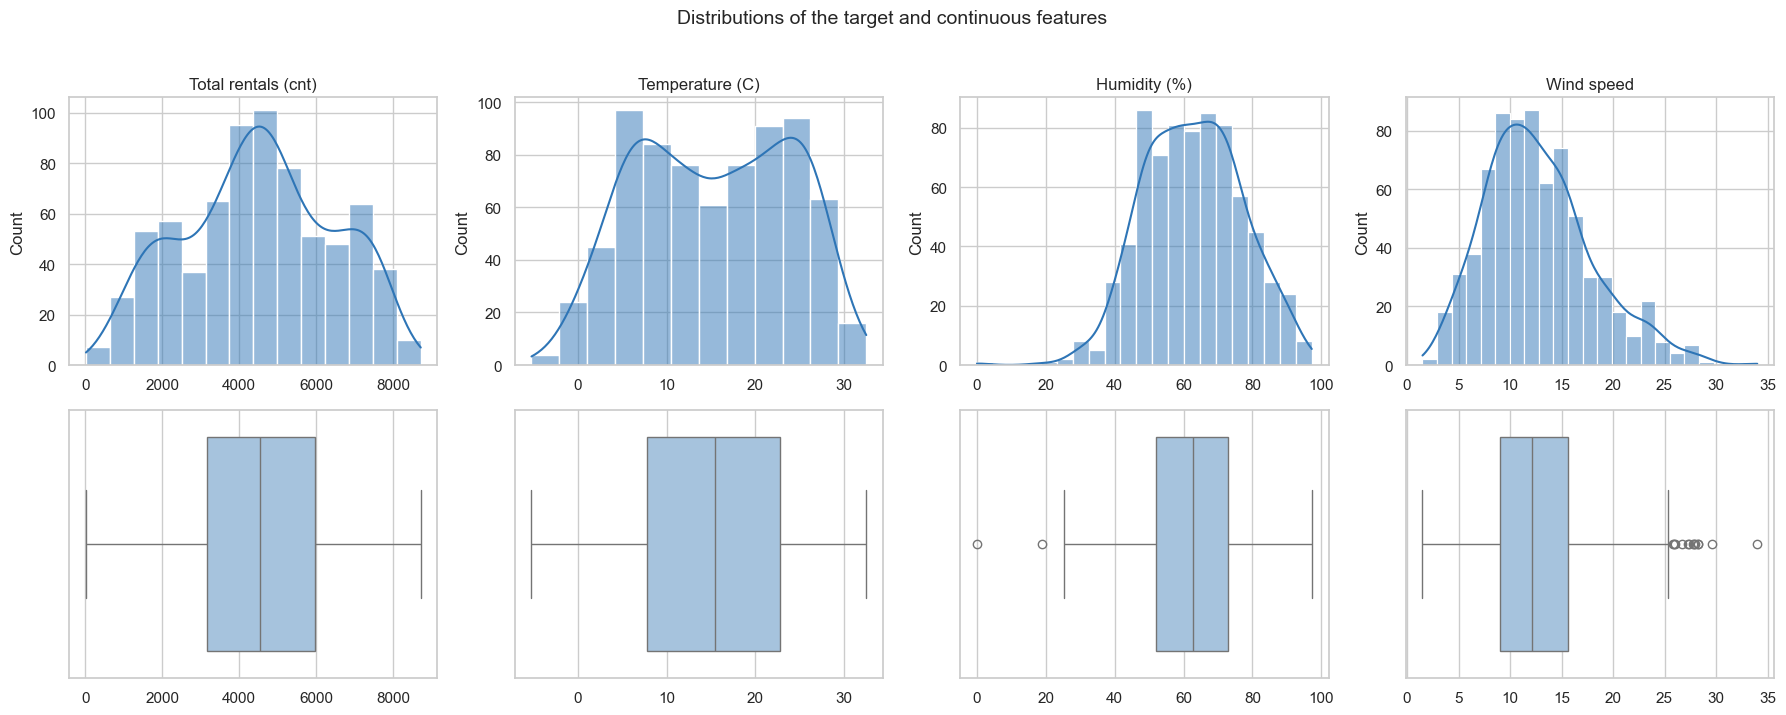

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, (col, lab) in zip(axes[0], [("cnt", "Total rentals (cnt)"), ("temp_c", "Temperature (C)"),
                                    ("hum_pct", "Humidity (%)"), ("wind_kmh", "Wind speed")]):
    sns.histplot(df[col], kde=True, ax=ax, color="#2E75B6"); ax.set_title(lab); ax.set_xlabel("")
for ax, col in zip(axes[1], ["cnt", "temp_c", "hum_pct", "wind_kmh"]):
    sns.boxplot(x=df[col], ax=ax, color="#9DC3E6"); ax.set_xlabel("")
plt.suptitle("Distributions of the target and continuous features", y=1.02, fontsize=14)
plt.tight_layout()
print("Skewness:", df[["cnt", "temp_c", "hum_pct", "wind_kmh", "casual", "registered"]].skew().round(2).to_dict())

- `cnt` is almost symmetric (skew ≈ 0), so **no log-transform of the target is required**.
- `windspeed` is mildly right-skewed (0.68) and `casual` strongly so (1.27) — people who ride only occasionally are very weather- and weekend-dependent.
- `temp` and `hum` are roughly bell-shaped.

### 4.2 Rentals by season, weather, year, month, weekday and day type

Days per weather class:
 weather_lbl
Clear              463
Mist/Cloudy        247
Light Snow/Rain     21

Mean cnt by weather:
 weather_lbl
Clear              4877.0
Light Snow/Rain    1803.0
Mist/Cloudy        4036.0


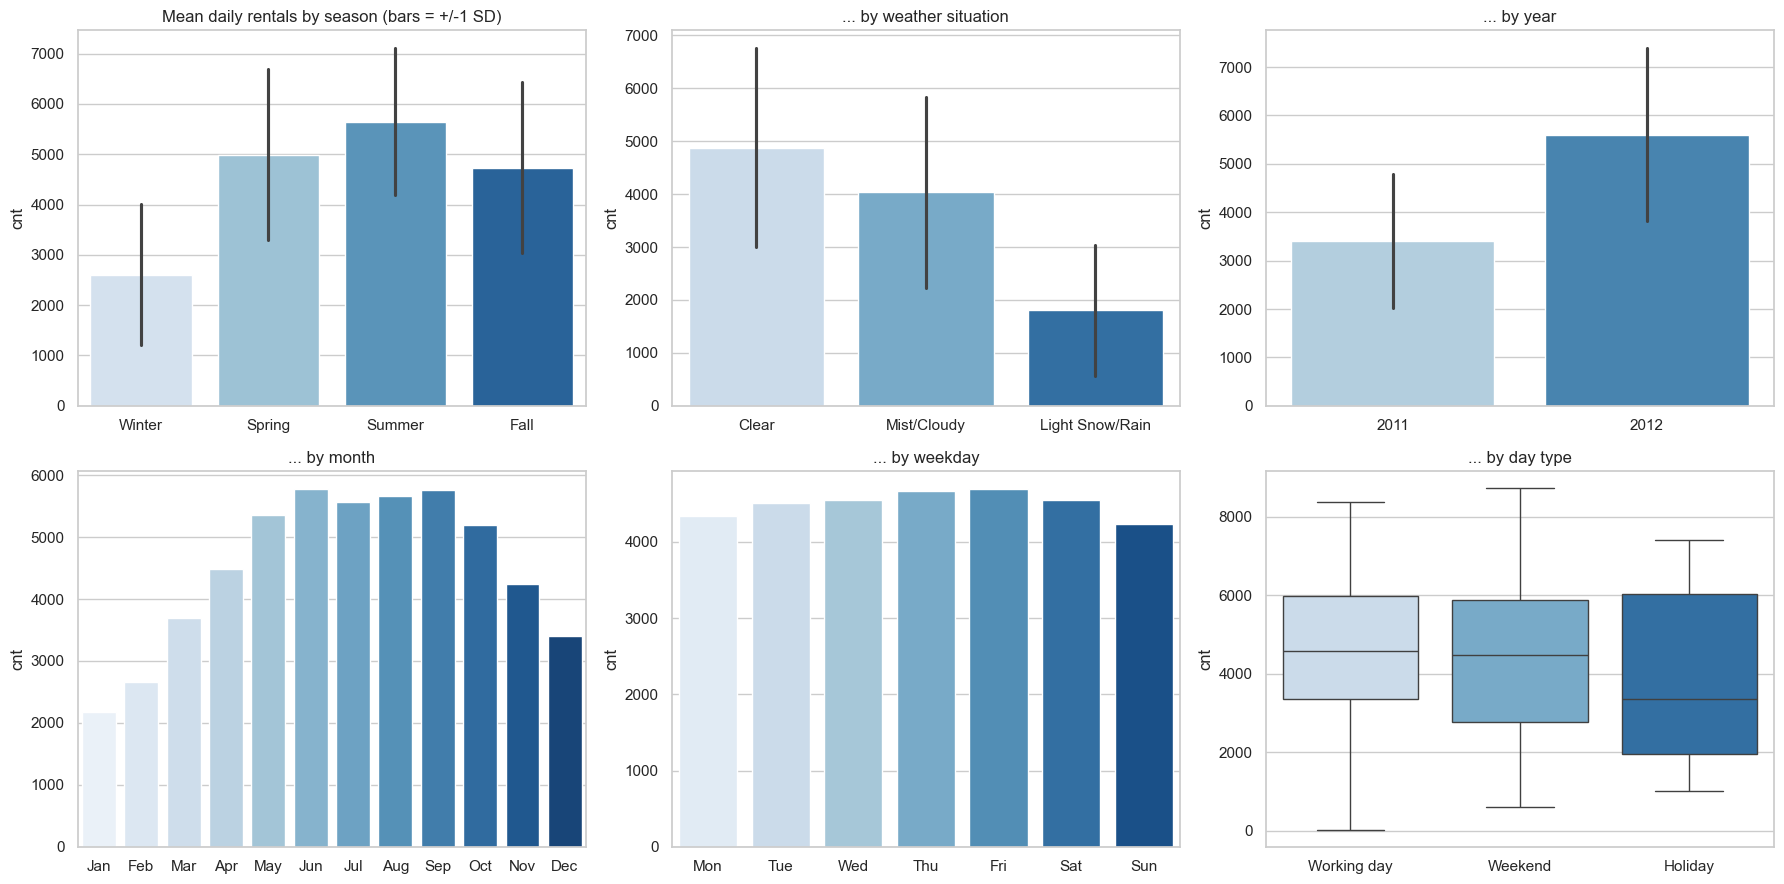

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
order_s = ["Winter", "Spring", "Summer", "Fall"]
order_w = ["Clear", "Mist/Cloudy", "Light Snow/Rain"]
order_d = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
order_m = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

sns.barplot(data=df, x="season_lbl", y="cnt", order=order_s, ax=axes[0,0], palette="Blues", errorbar="sd")
axes[0,0].set_title("Mean daily rentals by season (bars = +/-1 SD)")
sns.barplot(data=df, x="weather_lbl", y="cnt", order=order_w, ax=axes[0,1], palette="Blues", errorbar="sd")
axes[0,1].set_title("... by weather situation")
sns.barplot(data=df, x="yr_lbl", y="cnt", ax=axes[0,2], palette="Blues", errorbar="sd")
axes[0,2].set_title("... by year")
sns.barplot(data=df, x="month_lbl", y="cnt", order=order_m, ax=axes[1,0], palette="Blues", errorbar=None)
axes[1,0].set_title("... by month")
sns.barplot(data=df, x="weekday_lbl", y="cnt", order=order_d, ax=axes[1,1], palette="Blues", errorbar=None)
axes[1,1].set_title("... by weekday")
sns.boxplot(data=df.assign(day_type=np.where(df.holiday==1, "Holiday", np.where(df.workingday==1, "Working day", "Weekend"))),
            x="day_type", y="cnt", order=["Working day", "Weekend", "Holiday"], ax=axes[1,2], palette="Blues")
axes[1,2].set_title("... by day type")
for a in axes.ravel(): a.set_xlabel("")
plt.tight_layout()

print("Days per weather class:\n", df["weather_lbl"].value_counts().to_string())
print("\nMean cnt by weather:\n", df.groupby("weather_lbl")["cnt"].mean().round(0).to_string())

- **Season / month:** rentals rise from winter into summer and fall and drop again in December–January — a clear annual cycle.
- **Weather:** the worse the weather the fewer the rentals — Clear ≈ **4,877**/day, Mist/Cloudy ≈ **4,036**, Light Snow/Rain ≈ **1,803** (only 21 such days).
- **Year:** 2012 is far above 2011.
- **Weekday / working day:** surprisingly flat on average; working vs. non-working day matters much less than weather or season (tested formally in 4.7).

### 4.3 Trend over time

            sum    mean
yr_lbl                 
2011    1243103  3406.0
2012    2049576  5600.0

Year-on-year growth in average daily rentals: 64.4%


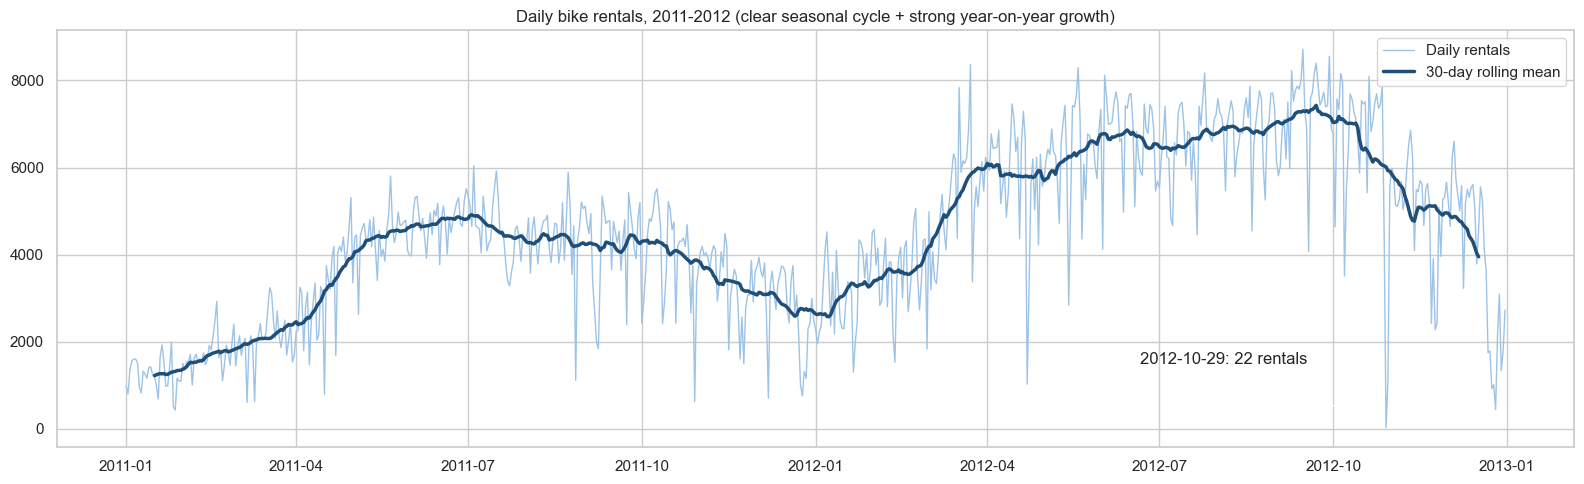

In [43]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df["dteday"], df["cnt"], color="#9DC3E6", lw=1, label="Daily rentals")
ax.plot(df["dteday"], df["cnt"].rolling(30, center=True).mean(), color="#1F4E79", lw=2.5, label="30-day rolling mean")
low = df.nsmallest(1, "cnt").iloc[0]
ax.annotate(f"{low.dteday.date()}: {int(low.cnt)} rentals", xy=(low.dteday, low.cnt),
            xytext=(low.dteday - pd.Timedelta(days=130), 1500), arrowprops=dict(arrowstyle="->"))
ax.set_title("Daily bike rentals, 2011-2012 (clear seasonal cycle + strong year-on-year growth)")
ax.legend(); plt.tight_layout()

g = df.groupby("yr_lbl")["cnt"].agg(["sum", "mean"])
print(g.round(0))
print(f"\nYear-on-year growth in average daily rentals: {g.loc['2012','mean']/g.loc['2011','mean']-1:.1%}")

Two things are visible: a strong **seasonal wave** and a **structural growth trend** — average daily rentals grew by **64 %** from 3,406 (2011) to 5,600 (2012). The system was still expanding, so the year indicator is the single most important predictor (confirmed in Section 8). It also means a model trained on 2011–12 cannot know the level of 2013 — see the production notes in Section 9.

### 4.4 Relationship with continuous weather variables

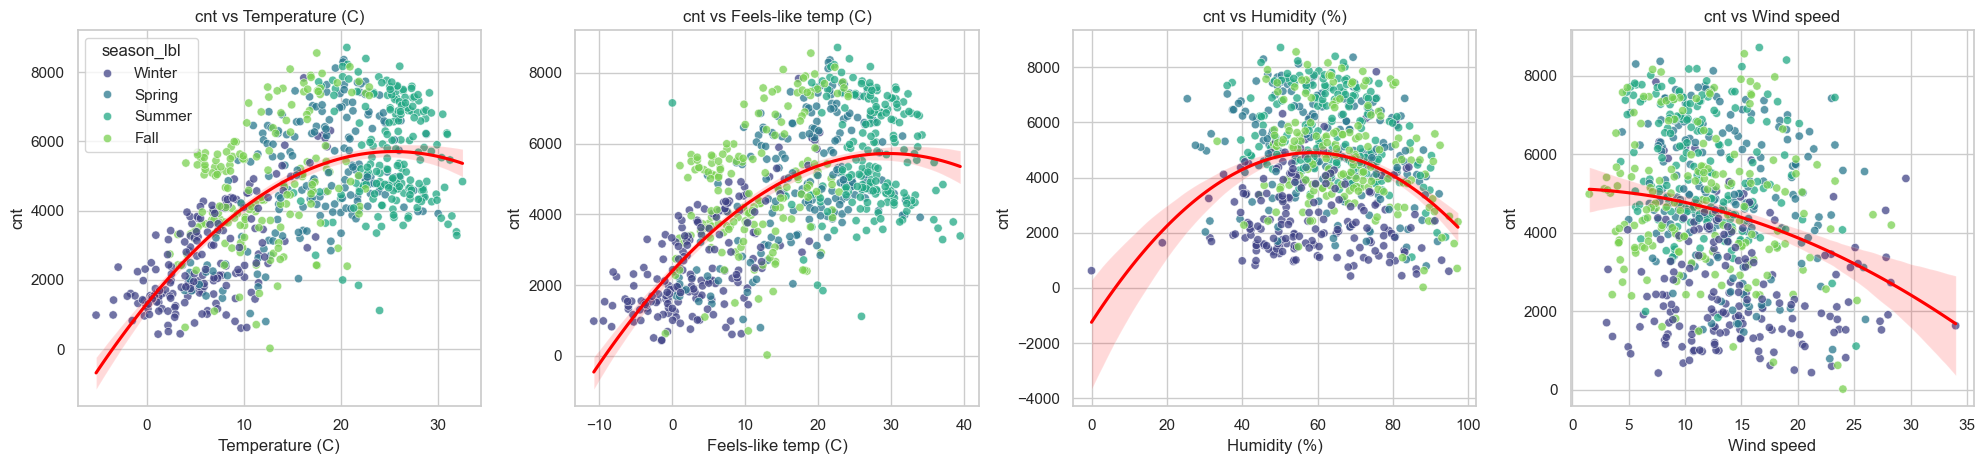

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, (col, lab) in zip(axes, [("temp_c", "Temperature (C)"), ("atemp_c", "Feels-like temp (C)"),
                                  ("hum_pct", "Humidity (%)"), ("wind_kmh", "Wind speed")]):
    sns.scatterplot(data=df, x=col, y="cnt", hue="season_lbl", hue_order=["Winter","Spring","Summer","Fall"],
                    palette="viridis", alpha=.75, ax=ax, legend=(col == "temp_c"))
    sns.regplot(data=df, x=col, y="cnt", scatter=False, color="red", ax=ax, order=2)
    ax.set_title(f"cnt vs {lab}"); ax.set_xlabel(lab)
plt.tight_layout()

- **Temperature** has the strongest relationship: rentals increase with temperature, then flatten/decline in the hottest days (curvature → linear models will under-fit, non-linear models will do better).
- **Humidity** has a weak negative effect; **wind speed** a moderate negative effect.
- The scatter shows two parallel "bands" because 2012 is shifted upward relative to 2011 — again the year effect.

### 4.5 Casual vs registered users

Registered share of all rentals: 81.2%
                 casual  registered
Non-working day    31.7        68.3
Working day        13.2        86.8


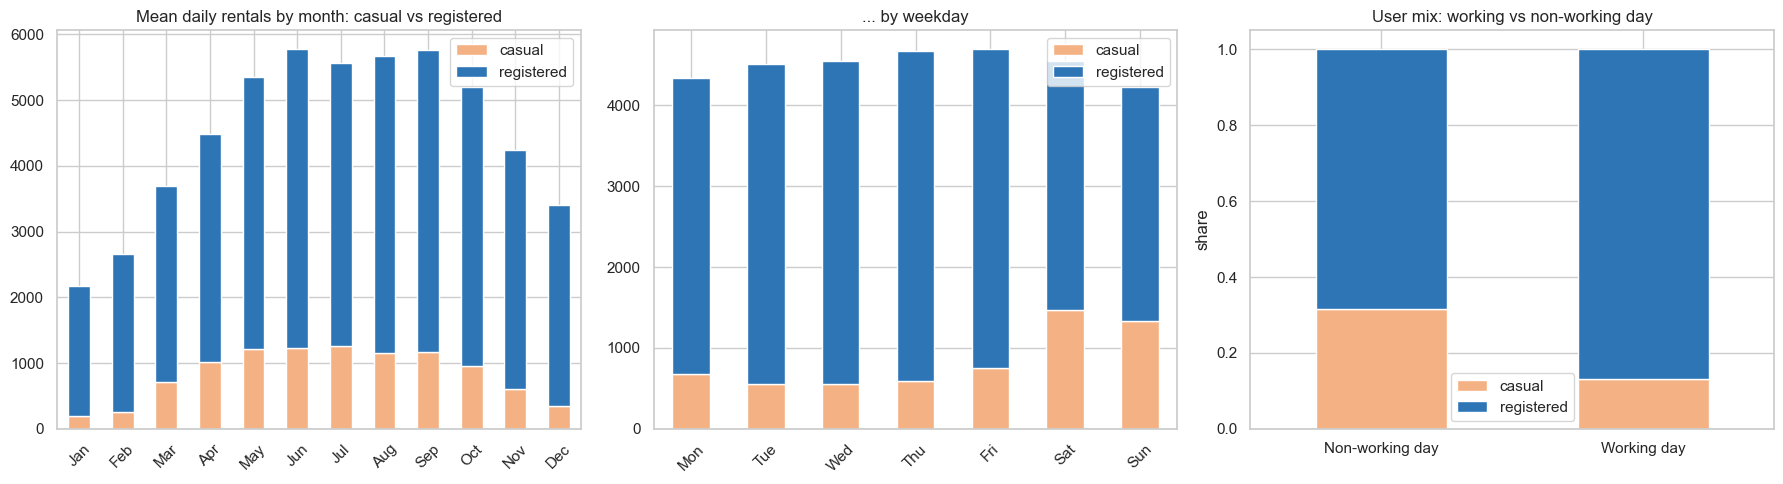

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
m = df.groupby("month_lbl")[["casual", "registered"]].mean().reindex(order_m)
m.plot(kind="bar", stacked=True, ax=axes[0], color=["#F4B183", "#2E75B6"]); axes[0].set_title("Mean daily rentals by month: casual vs registered")
w = df.groupby("weekday_lbl")[["casual", "registered"]].mean().reindex(order_d)
w.plot(kind="bar", stacked=True, ax=axes[1], color=["#F4B183", "#2E75B6"]); axes[1].set_title("... by weekday")
tot = df.groupby("workingday")[["casual", "registered"]].sum()
share = tot.div(tot.sum(axis=1), axis=0)
share.index = ["Non-working day", "Working day"]
share.plot(kind="bar", stacked=True, ax=axes[2], color=["#F4B183", "#2E75B6"]); axes[2].set_title("User mix: working vs non-working day"); axes[2].set_ylabel("share")
for a in axes: a.set_xlabel(""); a.tick_params(axis="x", rotation=0 if a is axes[2] else 45)
plt.tight_layout()
print("Registered share of all rentals:", f"{df.registered.sum()/df.cnt.sum():.1%}")
print((share * 100).round(1))

- **81 %** of rentals come from registered users (commuters); casual users are the minority but are much more seasonal.
- On **working days** casual users are only 13 % of rentals, on **weekends/holidays** 32 % — casual riders are leisure riders, registered riders are commuters.
- This is why total `cnt` barely differs between working and non-working days: the two user groups offset each other.

### 4.6 Correlation analysis

Correlation with cnt:
 registered    0.946
casual        0.673
atemp         0.631
temp          0.627
yr            0.567
season        0.406
mnth          0.280
weekday       0.067
workingday    0.061
holiday      -0.068
hum          -0.101
windspeed    -0.235
weathersit   -0.297

corr(temp, atemp) = 0.992


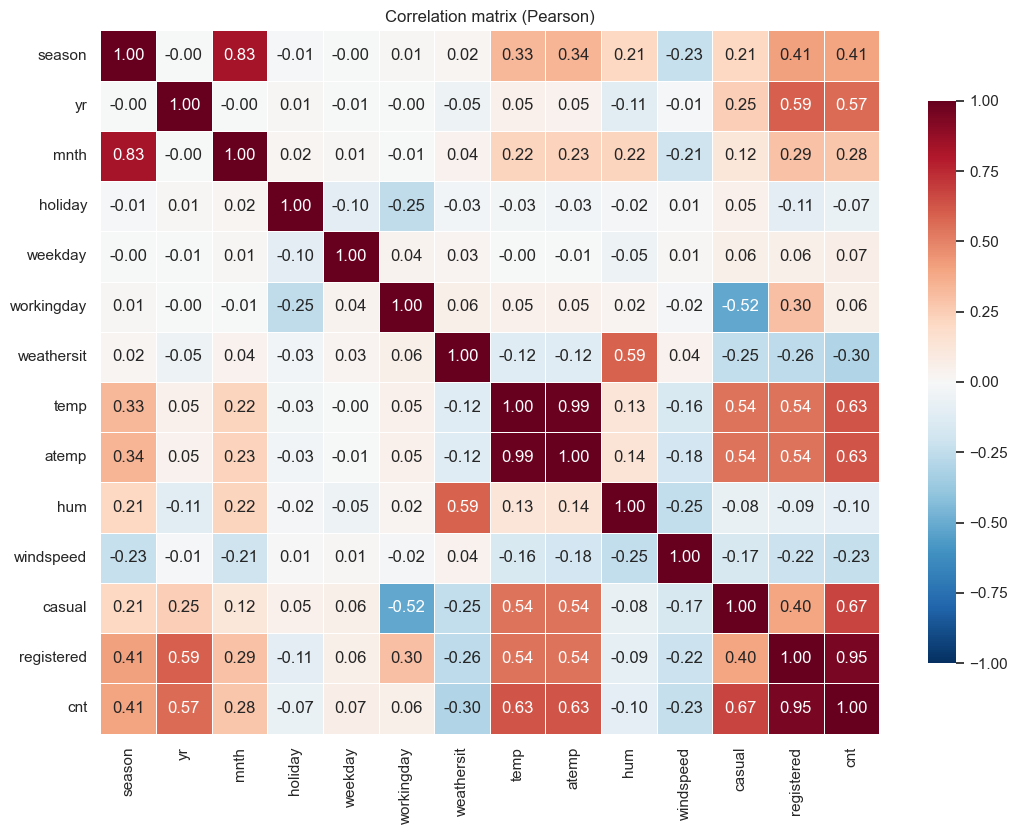

In [46]:
num_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit",
            "temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
corr = df[num_cols].corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation matrix (Pearson)")
plt.tight_layout()
print("Correlation with cnt:\n", corr["cnt"].drop("cnt").sort_values(ascending=False).round(3).to_string())
print("\ncorr(temp, atemp) =", round(corr.loc["temp", "atemp"], 3))

- Strongest drivers of `cnt`: **temp (0.63) / atemp (0.63)**, **year (0.57)**, **season (0.41)**; negative: **weather situation (−0.30)**, **wind speed (−0.24)**, humidity (−0.10).
- `registered` (0.95) and `casual` (0.67) correlate highly *by construction* — excluded to prevent leakage.
- **`temp` and `atemp` correlate at 0.99** → near-perfect multicollinearity; one must be dropped (Section 6).

### 4.7 Intraday patterns from the hourly file

Peak hours on working days : {17: 525.0, 18: 492.0, 8: 477.0}
Peak hours on weekends     : {13: 373.0, 12: 366.0, 14: 365.0}


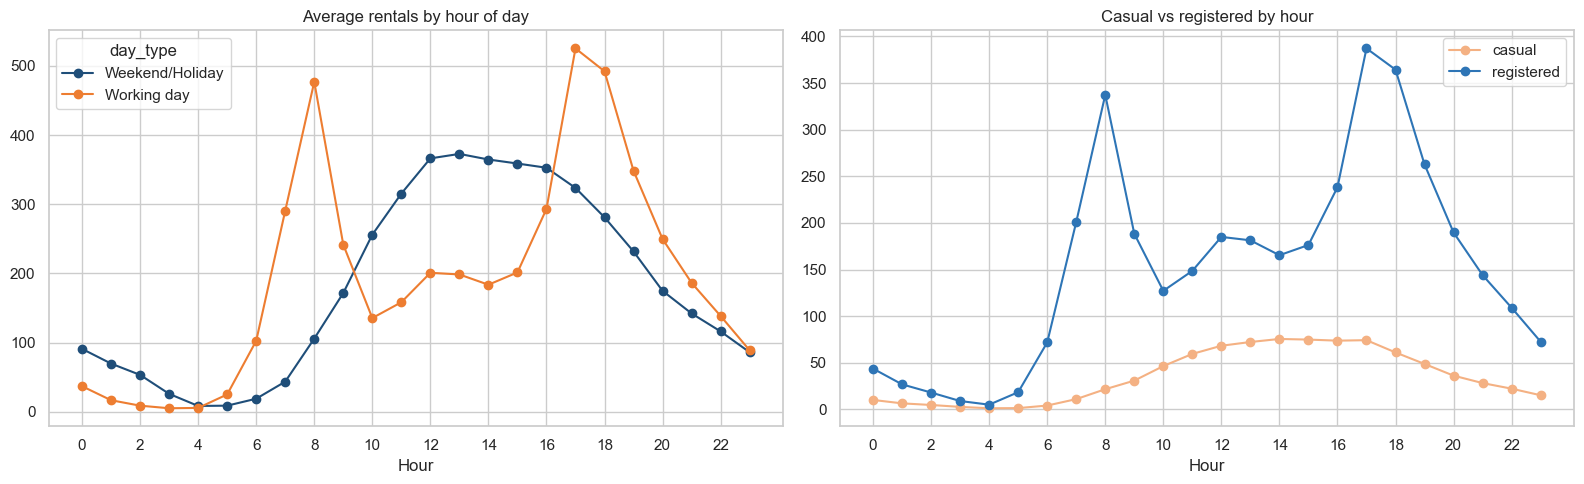

In [47]:
h = hour.copy()
h["day_type"] = np.where(h["workingday"] == 1, "Working day", "Weekend/Holiday")
prof = h.groupby(["hr", "day_type"])["cnt"].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
prof.plot(ax=axes[0], marker="o", color=["#1F4E79", "#ED7D31"]); axes[0].set_title("Average rentals by hour of day")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("Hour")
h.groupby("hr")[["casual", "registered"]].mean().plot(ax=axes[1], marker="o", color=["#F4B183", "#2E75B6"])
axes[1].set_title("Casual vs registered by hour"); axes[1].set_xticks(range(0, 24, 2)); axes[1].set_xlabel("Hour")
plt.tight_layout()
print("Peak hours on working days :", prof["Working day"].nlargest(3).round(0).to_dict())
print("Peak hours on weekends     :", prof["Weekend/Holiday"].nlargest(3).round(0).to_dict())

The hourly view explains the user-type split: **working days show a twin commute peak (~08:00 and 17:00–18:00)** driven by registered users, whereas **weekends have a single broad midday peak (12:00–14:00)** driven by casual users. (The daily target hides this because both patterns sum to similar daily totals.)

### 4.8 Statistical hypothesis tests

In [48]:
# 1) Does weather matter? One-way ANOVA + Kruskal-Wallis (non-parametric check)
groups = [g["cnt"].values for _, g in df.groupby("weathersit")]
print("Weather -> ANOVA F=%.2f, p=%.2e | Kruskal H=%.2f, p=%.2e" % (*stats.f_oneway(*groups), *stats.kruskal(*groups)))

# 2) Season
groups = [g["cnt"].values for _, g in df.groupby("season")]
print("Season  -> ANOVA F=%.2f, p=%.2e | Kruskal H=%.2f, p=%.2e" % (*stats.f_oneway(*groups), *stats.kruskal(*groups)))

# 3) Working day vs not (Welch t-test)
a, b = df.loc[df.workingday == 1, "cnt"], df.loc[df.workingday == 0, "cnt"]
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"Working vs non-working day -> mean {a.mean():.0f} vs {b.mean():.0f}, Welch t={t:.2f}, p={p:.3f}")

# 4) 2012 vs 2011
a, b = df.loc[df.yr == 1, "cnt"], df.loc[df.yr == 0, "cnt"]
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"2012 vs 2011 -> mean {a.mean():.0f} vs {b.mean():.0f}, Welch t={t:.2f}, p={p:.2e}")

# 5) Pearson / Spearman with continuous features
for c in ["temp", "hum", "windspeed"]:
    r, pr = stats.pearsonr(df[c], df["cnt"]); rho, ps = stats.spearmanr(df[c], df["cnt"])
    print(f"cnt vs {c:<9}: Pearson r={r:+.3f} (p={pr:.1e}) | Spearman rho={rho:+.3f}")

Weather -> ANOVA F=40.07, p=3.11e-17 | Kruskal H=67.18, p=2.59e-15
Season  -> ANOVA F=128.77, p=6.72e-67 | Kruskal H=250.93, p=4.11e-54
Working vs non-working day -> mean 4585 vs 4330, Welch t=1.60, p=0.110
2012 vs 2011 -> mean 5600 vs 3406, Welch t=18.58, p=1.05e-62
cnt vs temp     : Pearson r=+0.627 (p=2.8e-81) | Spearman rho=+0.622
cnt vs hum      : Pearson r=-0.101 (p=6.5e-03) | Spearman rho=-0.098
cnt vs windspeed: Pearson r=-0.235 (p=1.4e-10) | Spearman rho=-0.217


| Question | Test | Result |
|---|---|---|
| Does weather change rentals? | ANOVA + Kruskal-Wallis | **Yes**, p ≈ 3·10⁻¹⁷ |
| Does season change rentals? | ANOVA + Kruskal-Wallis | **Yes**, p ≈ 7·10⁻⁶⁷ |
| Working vs non-working day | Welch t-test | **No significant difference** (4,585 vs 4,330, p = 0.11) |
| 2012 vs 2011 | Welch t-test | **Yes**, p ≈ 10⁻⁶² (+64 %) |
| Temperature / wind / humidity | Pearson & Spearman | temp strongly positive, wind & humidity weak negative; both coefficients agree → relationships are monotonic |

### 4.9 Key business insights
1. **Temperature, season and weather are the demand drivers** — a ride-share operator should plan bike redistribution and maintenance around them.
2. **The service grew 64 % in one year**; growth, not just weather, explains much of the variation.
3. **Two distinct customers:** weekday commuters (registered) and weekend leisure riders (casual) — different marketing and availability needs (e.g. more bikes at commute hubs 08:00 & 17:00, at leisure hubs on weekend midday).
4. **Rain/snow days are rare but devastating** (−60 % vs clear days) and extreme events (Hurricane Sandy) cause near-zero usage that weather codes alone cannot predict.

## 5. Feature Engineering & Pre-processing (Task 2 starts here)

| Decision | Reason |
|---|---|
| Drop `casual`, `registered` | **Target leakage** (`cnt` is their sum) |
| Drop `instant`, `dteday` | Record index / raw date; year, month, weekday, season are already encoded |
| Drop `atemp` | r = 0.99 with `temp`; VIF ≈ 64 → ≈ 1 after dropping (computed below) |
| Fix `hum = 0` | One impossible sensor value → interpolate from neighbouring days |
| One-hot encode `season, mnth, weekday, weathersit` | They are categories; numeric codes would imply a false order/distance (e.g. "Fall = 4 is twice Spring = 2") |
| Standardise `temp, hum, windspeed` | Needed by distance/kernel/regularised models (KNN, SVR, Ridge, Lasso); harmless for trees |
| Keep `yr, holiday, workingday` as 0/1 flags | Already binary |
| All transformations inside a `Pipeline` | Fitted on training folds only → **no leakage inside cross-validation** |

In [49]:
# ---- Target and features -------------------------------------------------------------------
TARGET = "cnt"
LEAKAGE = ["casual", "registered"]          # cnt = casual + registered -> would leak the answer
IDENTIFIERS = ["instant", "dteday"]         # record index / raw date (month, year, weekday already encoded)
REDUNDANT = ["atemp"]                       # r(temp, atemp) ~ 0.99 -> multicollinearity

# ---- Fix the impossible humidity = 0 reading (2011-03-10) by interpolating between neighbouring days ----
day_model = day.copy()
bad = day_model["hum"] == 0
day_model.loc[bad, "hum"] = np.nan
day_model["hum"] = day_model["hum"].interpolate()
print("Humidity fixed on", int(bad.sum()), "row(s) ->", day_model.loc[bad, ["dteday", "hum"]].round(3).to_dict("records"))

feature_df = day_model.drop(columns=LEAKAGE + IDENTIFIERS + REDUNDANT + [TARGET])
print("Features used:", list(feature_df.columns))

# ---- Variance Inflation Factor (computed with plain OLS, no extra libraries) ---------------
def vif_table(X):
    out = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        out[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out).sort_values(ascending=False).round(2)

with_atemp = day[["temp", "atemp", "hum", "windspeed"]]
print("\nVIF WITH atemp   :", vif_table(with_atemp).to_dict())
print("VIF WITHOUT atemp:", vif_table(with_atemp.drop(columns="atemp")).to_dict())

Humidity fixed on 1 row(s) -> [{'dteday': '2011-03-10', 'hum': 0.712}]
Features used: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed']

VIF WITH atemp   : {'atemp': 63.63, 'temp': 62.97, 'windspeed': 1.13, 'hum': 1.08}
VIF WITHOUT atemp: {'windspeed': 1.08, 'hum': 1.07, 'temp': 1.03}


In [50]:
X = feature_df.copy()
y = day[TARGET].copy()

# Categorical codes that are NOT ordinal in nature get one-hot encoded; binary flags pass through
cat_cols = ["season", "mnth", "weekday", "weathersit"]
bin_cols = ["yr", "holiday", "workingday"]
num_cols_m = ["temp", "hum", "windspeed"]

def make_preprocessor(scale=True):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols_m),
        ("bin", "passthrough", bin_cols),
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Target mean  train/test:", round(y_train.mean()), "/", round(y_test.mean()))
print("Encoded feature count :", make_preprocessor().fit(X_train).get_feature_names_out().shape[0])

Train: (584, 10) | Test: (147, 10)
Target mean  train/test: 4561 / 4279
Encoded feature count : 32


## 6. Model Building

Eleven candidates covering linear, instance-based, kernel, single-tree, bagging and boosting families:
Linear Regression, Ridge, Lasso, ElasticNet, KNN, SVR (RBF), Decision Tree, Random Forest, Extra Trees, Gradient Boosting, HistGradientBoosting (+ **XGBoost automatically, if it is installed** — it was not available in the environment where this notebook was executed, so the results below do not include it).

### 6.1 Baseline — default hyper-parameters, 5-fold CV on the training set
*Note on SVR:* its target must also be standardised (its `C`/`epsilon` are expressed in target units). Without this, the very first run gave **CV R² ≈ 0.00**; with `TransformedTargetRegressor` it becomes 0.885 — see the challenges report.

In [51]:
def pipe(model, scale=True):
    return Pipeline([("prep", make_preprocessor(scale)), ("model", model)])

models = {
    "Linear Regression":      pipe(LinearRegression()),
    "Ridge":                  pipe(Ridge(alpha=1.0)),
    "Lasso":                  pipe(Lasso(alpha=1.0, max_iter=20000)),
    "ElasticNet":             pipe(ElasticNet(alpha=1.0, l1_ratio=.5, max_iter=20000)),
    "KNN":                    pipe(KNeighborsRegressor(n_neighbors=7)),
    # SVR is not scale-invariant in the TARGET either (epsilon/C are in target units) -> standardise y as well
    "SVR (RBF)":              TransformedTargetRegressor(regressor=pipe(SVR(C=1.0)), transformer=StandardScaler()),
    "Decision Tree":          pipe(DecisionTreeRegressor(random_state=RANDOM_STATE), scale=False),
    "Random Forest":          pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    "Extra Trees":            pipe(ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    "Gradient Boosting":      pipe(GradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
    "HistGradientBoosting":   pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}
# XGBoost is used automatically if it is installed in your environment (pip install xgboost)
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = pipe(XGBRegressor(n_estimators=300, learning_rate=.05, max_depth=3, subsample=.8,
                                          colsample_bytree=.8, random_state=RANDOM_STATE, n_jobs=-1), scale=False)
    print("XGBoost found and added.")
except ImportError:
    print("XGBoost not installed - skipping (pip install xgboost to include it).")

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
    rows.append({"Model": name, "CV R2": s["test_r2"].mean(), "CV R2 std": s["test_r2"].std(),
                 "CV RMSE": -s["test_neg_root_mean_squared_error"].mean(), "CV MAE": -s["test_neg_mean_absolute_error"].mean()})
baseline = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
baseline.round(3)

XGBoost found and added.


,Model,CV R2,CV R2 std,CV RMSE,CV MAE
0,SVR (RBF),0.885,0.020,642.891,451.104
1,XGBoost,0.876,0.029,662.564,472.432
2,HistGradientBoosting,0.870,0.034,673.260,484.991
3,Gradient Boosting,0.873,0.029,673.475,491.080
4,Random Forest,0.856,0.027,715.642,509.995
5,Extra Trees,0.847,0.031,737.176,519.049
6,Ridge,0.822,0.032,796.865,586.183
7,Lasso,0.821,0.032,798.944,586.647
8,Linear Regression,0.820,0.034,800.580,587.704
9,Decision Tree,0.750,0.059,939.502,685.617


Even before tuning, **boosting, SVR and bagged trees clearly beat the linear models** (CV R² 0.85–0.89 vs ≈ 0.82), confirming the non-linear weather/season effects seen in EDA. KNN, single Decision Tree and ElasticNet (default alpha over-shrinks) are weak.

### 6.2 Hyper-parameter tuning
`RandomizedSearchCV`, 5-fold CV, optimising RMSE, on the **training set only** — the test set is never touched here.

In [52]:
param_spaces = {
    "Ridge": ({"model__alpha": np.logspace(-2, 3, 30)}, 30),
    "Lasso": ({"model__alpha": np.logspace(-2, 3, 30)}, 30),
    "SVR (RBF)": ({"regressor__model__C": np.logspace(-1, 2, 12), "regressor__model__gamma": np.logspace(-3, 0, 10),
                   "regressor__model__epsilon": [0.01, 0.05, 0.1, 0.2]}, 40),
    "KNN": ({"model__n_neighbors": range(3, 25), "model__weights": ["uniform", "distance"]}, 30),
    "Decision Tree": ({"model__max_depth": range(3, 15), "model__min_samples_leaf": [1, 3, 5, 10, 20]}, 30),
    "Random Forest": ({"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 8, 12, 16],
                       "model__min_samples_leaf": [1, 2, 3, 5], "model__max_features": [0.4, 0.6, 0.8, 1.0]}, 30),
    "Extra Trees": ({"model__n_estimators": [200, 400, 600], "model__max_depth": [None, 8, 12, 16],
                     "model__min_samples_leaf": [1, 2, 3, 5], "model__max_features": [0.4, 0.6, 0.8, 1.0]}, 30),
    "Gradient Boosting": ({"model__n_estimators": [150, 300, 500], "model__learning_rate": [0.02, 0.05, 0.1],
                           "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.85, 1.0],
                           "model__min_samples_leaf": [1, 3, 5]}, 30),
    "HistGradientBoosting": ({"model__learning_rate": [0.02, 0.05, 0.1], "model__max_depth": [2, 3, 4, None],
                              "model__max_iter": [150, 300, 500], "model__min_samples_leaf": [5, 10, 20],
                              "model__l2_regularization": [0, 0.1, 1.0]}, 30),
}
if "XGBoost" in models:
    param_spaces["XGBoost"] = ({"model__n_estimators": [200, 400, 600], "model__learning_rate": [0.02, 0.05, 0.1],
                                "model__max_depth": [2, 3, 4, 5], "model__subsample": [0.7, 0.85, 1.0],
                                "model__colsample_bytree": [0.6, 0.8, 1.0]}, 30)

tuned, best_params = {}, {}
for name, (space, n_iter) in param_spaces.items():
    rs = RandomizedSearchCV(models[name], space, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_train, y_train)
    tuned[name] = rs.best_estimator_
    best_params[name] = {k.split("model__")[-1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                         for k, v in rs.best_params_.items()}
    print(f"{name:<22} best CV RMSE = {-rs.best_score_:7.1f}   {best_params[name]}")

# models with no hyper-parameters to tune are carried over unchanged
for name in ["Linear Regression", "ElasticNet"]:
    tuned[name] = models[name].fit(X_train, y_train)

Ridge                  best CV RMSE =   793.7   {'alpha': 3.8566}
Lasso                  best CV RMSE =   798.6   {'alpha': 3.8566}
SVR (RBF)              best CV RMSE =   674.6   {'gamma': 0.01, 'epsilon': 0.1, 'C': 53.367}
KNN                    best CV RMSE =   981.0   {'weights': 'distance', 'n_neighbors': 9}
Decision Tree          best CV RMSE =   858.6   {'min_samples_leaf': 5, 'max_depth': 13}
Random Forest          best CV RMSE =   673.3   {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': 16}
Extra Trees            best CV RMSE =   714.3   {'n_estimators': 400, 'min_samples_leaf': 2, 'max_features': 0.6, 'max_depth': None}
Gradient Boosting      best CV RMSE =   654.4   {'subsample': 0.7, 'n_estimators': 150, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.05}
HistGradientBoosting   best CV RMSE =   668.6   {'min_samples_leaf': 20, 'max_iter': 300, 'max_depth': 3, 'learning_rate': 0.1, 'l2_regularization': 1.0}
XGBoost                best 

## 7. Final Evaluation on Unseen Data

### 7.1 Random 80/20 hold-out (147 test days)

In [53]:
def regression_metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MedAE": np.median(np.abs(y_true - y_pred))}

rows = []
for name, est in tuned.items():
    est.fit(X_train, y_train)
    tr = regression_metrics(y_train, est.predict(X_train))
    te = regression_metrics(y_test, est.predict(X_test))
    cvs = cross_val_score(est, X_train, y_train, cv=cv, scoring="r2")
    rows.append({"Model": name, "Train R2": tr["R2"], "CV R2": cvs.mean(), "Test R2": te["R2"],
                 "Test RMSE": te["RMSE"], "Test MAE": te["MAE"], "Test MedAE": te["MedAE"],
                 "Overfit gap (Train-Test R2)": tr["R2"] - te["R2"]})
results = pd.DataFrame(rows).sort_values("Test RMSE").reset_index(drop=True)
results.index = results.index + 1
results.round(3)

,Model,Train R2,CV R2,Test R2,Test RMSE,Test MAE,Test MedAE,Overfit gap (Train-Test R2)
1,SVR (RBF),0.922,0.872,0.913,591.872,407.527,297.274,0.010
2,XGBoost,0.978,0.883,0.903,623.911,416.504,294.549,0.075
3,Gradient Boosting,0.946,0.880,0.901,629.477,437.316,337.175,0.044
4,HistGradientBoosting,0.963,0.873,0.892,658.020,454.886,311.264,0.071
5,Random Forest,0.983,0.873,0.890,662.837,445.631,314.366,0.092
6,Extra Trees,0.975,0.857,0.871,718.709,474.126,320.091,0.103
7,Lasso,0.846,0.821,0.840,800.679,589.553,458.992,0.006
8,Linear Regression,0.847,0.820,0.840,801.153,586.767,476.758,0.007
9,Ridge,0.846,0.824,0.839,804.321,591.880,472.535,0.008
10,Decision Tree,0.931,0.794,0.817,857.450,555.395,379.625,0.114


Metrics: **R²** (variance explained), **RMSE** (penalises big misses, in bikes/day), **MAE** and **median absolute error** (typical miss). *MAPE was deliberately not used* — the 22-rental hurricane day produces a percentage error of >10,000 % that dominates the average and makes it meaningless (see challenges).

### 7.2 Chronological hold-out — a more realistic test
A random split lets the model see days from the *same weeks* it is tested on. In production the model must predict the **future**. Here every model is retrained on the first 80 % of days (to 2012-08-06) and tested on the last 20 % (Aug–Dec 2012).

In [54]:
# Robustness check: train on the EARLIER 80% of days, test on the LATEST 20% (what production really looks like)
cut = int(len(day) * 0.8)
Xc_tr, Xc_te, yc_tr, yc_te = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
print(f"Chronological split -> train {day.dteday.iloc[0]} .. {day.dteday.iloc[cut-1]} ({cut} days) | "
      f"test {day.dteday.iloc[cut]} .. {day.dteday.iloc[-1]} ({len(day)-cut} days)")

rows = []
for name, est in tuned.items():
    m = clone(est).fit(Xc_tr, yc_tr)
    r = regression_metrics(yc_te, m.predict(Xc_te))
    rows.append({"Model": name, "Chrono R2": r["R2"], "Chrono RMSE": r["RMSE"], "Chrono MAE": r["MAE"]})
chrono = pd.DataFrame(rows)
compare = results[["Model", "Test R2", "Test RMSE"]].merge(chrono, on="Model").sort_values("Chrono RMSE").reset_index(drop=True)
compare.round(3)

Chronological split -> train 2011-01-01 .. 2012-08-06 (584 days) | test 2012-08-07 .. 2012-12-31 (147 days)


,Model,Test R2,Test RMSE,Chrono R2,Chrono RMSE,Chrono MAE
0,SVR (RBF),0.913,591.872,0.743,950.167,667.708
1,XGBoost,0.903,623.911,0.728,976.924,805.152
2,HistGradientBoosting,0.892,658.020,0.718,994.869,830.395
3,Gradient Boosting,0.901,629.477,0.697,1031.102,877.614
4,Extra Trees,0.871,718.709,0.677,1066.096,812.146
5,Linear Regression,0.840,801.153,0.653,1104.477,806.056
6,Ridge,0.839,804.321,0.643,1119.750,845.402
7,Lasso,0.840,800.679,0.637,1129.875,841.484
8,Random Forest,0.890,662.837,0.630,1140.032,963.555
9,Decision Tree,0.817,857.450,0.438,1405.831,1142.337


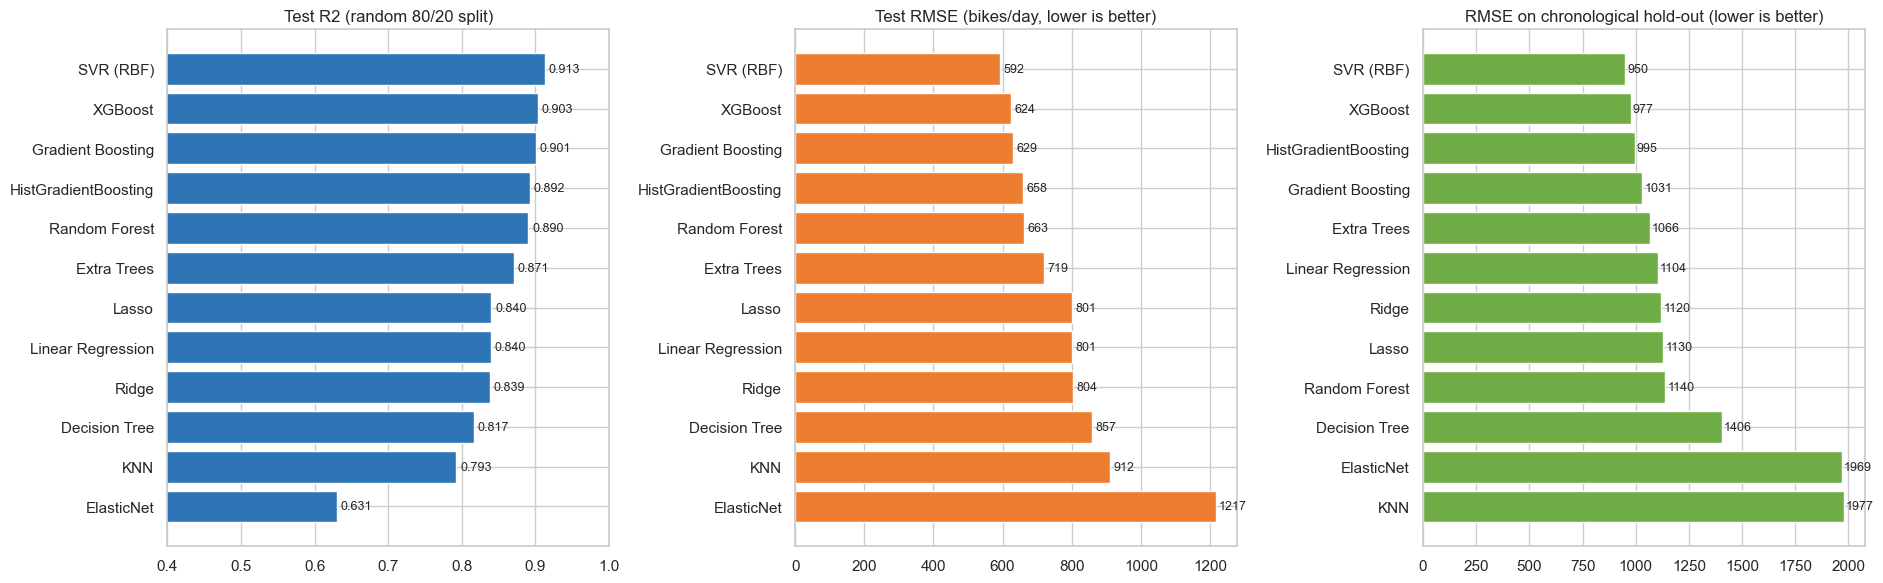

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
r = results.sort_values("Test R2")
axes[0].barh(r["Model"], r["Test R2"], color="#2E75B6"); axes[0].set_title("Test R2 (random 80/20 split)"); axes[0].set_xlim(0.4, 1)
for i, v in enumerate(r["Test R2"]): axes[0].text(v + .005, i, f"{v:.3f}", va="center", fontsize=9)
r = results.sort_values("Test RMSE", ascending=False)
axes[1].barh(r["Model"], r["Test RMSE"], color="#ED7D31"); axes[1].set_title("Test RMSE (bikes/day, lower is better)")
for i, v in enumerate(r["Test RMSE"]): axes[1].text(v + 10, i, f"{v:.0f}", va="center", fontsize=9)
c = compare.sort_values("Chrono RMSE", ascending=False)
axes[2].barh(c["Model"], c["Chrono RMSE"], color="#70AD47"); axes[2].set_title("RMSE on chronological hold-out (lower is better)")
for i, v in enumerate(c["Chrono RMSE"]): axes[2].text(v + 10, i, f"{v:.0f}", va="center", fontsize=9)
plt.tight_layout()

**Reading the two evaluations together**
- All models lose accuracy on the chronological split (e.g. SVR RMSE 592 → 950). That is expected: the future contains growth and a season-mix the model never saw, and it gives a **more honest estimate of production error**.
- The **ranking is stable at the top**: SVR, HistGradientBoosting, Gradient Boosting and Extra Trees stay ahead of the linear models, while KNN and ElasticNet collapse (negative R²) — distance-based/over-shrunk models cannot extrapolate to unseen periods.

## 8. Best-Model Diagnostics

The final choice uses the sum of ranks on both hold-out RMSEs, so a model must do well on *both* the random and the future-looking test.

               Model  Test RMSE  Chrono RMSE  rank_sum
           SVR (RBF)     591.87       950.17       2.0
             XGBoost     623.91       976.92       4.0
HistGradientBoosting     658.02       994.87       7.0
   Gradient Boosting     629.48      1031.10       7.0
         Extra Trees     718.71      1066.10      11.0

Selected model: SVR (RBF) | params: {'gamma': 0.01, 'epsilon': 0.1, 'C': 53.367}
Residual mean = -53.1, SD = 591.5, skew = -1.45
Hurricane Sandy (2012-10-29) is in the test set; RMSE with it = 592, without it = 536
Share of test days predicted within +/-10%: 61.2% | within +/-20%: 81.6%


,dteday,weathersit,temp,hum,windspeed,actual,predicted,abs_err
667,2012-10-29,3,0.440000,0.880000,0.358200,22,3109.0,3087.0
448,2012-03-24,2,0.502500,0.885417,0.192783,3372,5669.0,2297.0
327,2011-11-24,1,0.373333,0.549167,0.167304,1495,3165.0,1670.0
265,2011-09-23,2,0.609167,0.972500,0.078367,2395,3992.0,1597.0
550,2012-07-04,1,0.789167,0.538750,0.134950,7403,6105.0,1298.0


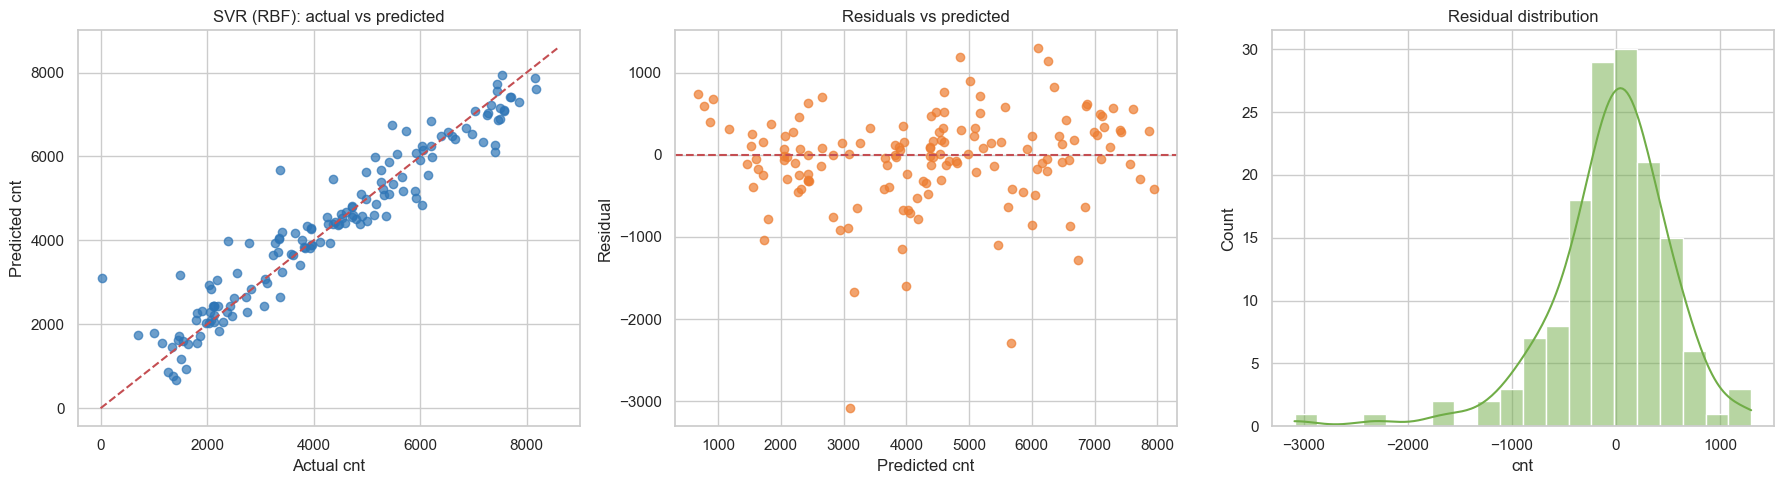

In [56]:
# Pick the production candidate: best combination of random-split test RMSE AND chronological RMSE
rank = compare.assign(rank_sum=compare["Test RMSE"].rank() + compare["Chrono RMSE"].rank()).sort_values("rank_sum")
print(rank[["Model", "Test RMSE", "Chrono RMSE", "rank_sum"]].head(5).round(2).to_string(index=False))
BEST_NAME = rank.iloc[0]["Model"]
best_model = tuned[BEST_NAME]
print("\nSelected model:", BEST_NAME, "| params:", best_params.get(BEST_NAME))

pred = best_model.predict(X_test)
res = y_test - pred
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, pred, alpha=.7, color="#2E75B6"); lim = [0, max(y_test.max(), pred.max()) * 1.05]
axes[0].plot(lim, lim, "r--"); axes[0].set_xlabel("Actual cnt"); axes[0].set_ylabel("Predicted cnt"); axes[0].set_title(f"{BEST_NAME}: actual vs predicted")
axes[1].scatter(pred, res, alpha=.7, color="#ED7D31"); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted cnt"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")
sns.histplot(res, kde=True, ax=axes[2], color="#70AD47"); axes[2].set_title("Residual distribution")
plt.tight_layout()
print(f"Residual mean = {res.mean():.1f}, SD = {res.std():.1f}, skew = {stats.skew(res):.2f}")
sandy = day.loc[X_test.index, "dteday"] == "2012-10-29"
if sandy.any():
    rm = np.sqrt(mean_squared_error(y_test[~sandy], pred[~sandy]))
    print(f"Hurricane Sandy (2012-10-29) is in the test set; RMSE with it = {np.sqrt((res**2).mean()):.0f}, without it = {rm:.0f}")
print("Share of test days predicted within +/-10%:", f"{(np.abs(res)/y_test <= .10).mean():.1%}",
      "| within +/-20%:", f"{(np.abs(res)/y_test <= .20).mean():.1%}")
worst = X_test.assign(actual=y_test, predicted=pred.round(0), abs_err=np.abs(res).round(0)).join(day["dteday"]).nlargest(5, "abs_err")
worst[["dteday", "weathersit", "temp", "hum", "windspeed", "actual", "predicted", "abs_err"]]

**Diagnostics**
- Predicted vs actual follows the diagonal; residuals are centred near zero with no strong funnel shape (no serious heteroscedasticity).
- The largest miss is **Hurricane Sandy (2012-10-29)**: 22 actual rentals vs ≈ 3,100 predicted. No variable in the data encodes "city-wide emergency", so no model could predict it. Excluding that single day, test RMSE falls from 592 to ≈ 536.
- Other large misses are days with very high humidity/mist (e.g. 2012-03-24) or unusual holiday-adjacent days (2011-11-24, Thanksgiving) — events that weather and calendar flags describe only partly.

yr            0.5173
temp          0.2630
season        0.1747
weathersit    0.0713
mnth          0.0712
hum           0.0687
windspeed     0.0355
weekday       0.0071
workingday    0.0040
holiday       0.0029
dtype: float64

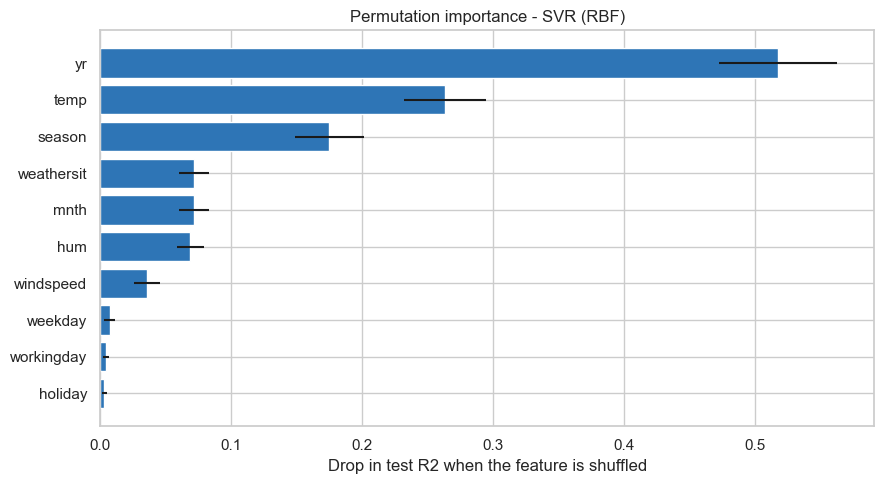

In [57]:
pi = permutation_importance(best_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(imp.index, imp.values, xerr=pi.importances_std[imp.index.map(list(X_test.columns).index)], color="#2E75B6")
plt.xlabel("Drop in test R2 when the feature is shuffled"); plt.title(f"Permutation importance - {BEST_NAME}")
plt.tight_layout()
imp.sort_values(ascending=False).round(4)

**What drives the predictions (permutation importance):** `yr` (growth) ≫ `temp` > `season` > `weathersit`, `mnth`, `hum` > `windspeed`. Weekday, working-day and holiday flags contribute almost nothing — consistent with the EDA finding that working vs non-working days show no significant difference in *total* rentals.

In [58]:
# Re-fit the selected pipeline on ALL available data (train + test) for deployment, then save it
final_model = clone(best_model).fit(X, y)
joblib.dump(final_model, "bike_rental_model.joblib")

# Example: predict a warm, clear Saturday in summer 2012
sample = pd.DataFrame([{"season": 3, "yr": 1, "mnth": 7, "holiday": 0, "weekday": 6, "workingday": 0,
                        "weathersit": 1, "temp": 0.75, "hum": 0.50, "windspeed": 0.15}])
loaded = joblib.load("bike_rental_model.joblib")
print("Saved -> bike_rental_model.joblib")
print("Predicted rentals for sample day:", int(loaded.predict(sample)[0]))

Saved -> bike_rental_model.joblib
Predicted rentals for sample day: 7291


## 9. Model Comparison Report

### 9.1 Results summary

| Rank | Model | Test R² | Test RMSE | Test MAE | Chrono R² | Chrono RMSE | Over-fit gap (Train−Test R²) |
|---|---|---|---|---|---|---|---|
| 1 | **SVR (RBF)** | **0.913** | **592** | **408** | **0.743** | **950** | **0.010** |
| 2 | Gradient Boosting | 0.901 | 629 | 437 | 0.697 | 1,031 | 0.044 |
| 3 | HistGradientBoosting | 0.892 | 658 | 455 | 0.718 | 995 | 0.071 |
| 4 | Random Forest | 0.890 | 663 | 446 | 0.630 | 1,140 | 0.092 |
| 5 | Extra Trees | 0.871 | 719 | 474 | 0.677 | 1,066 | 0.103 |
| 6 | Lasso / Linear / Ridge | ≈ 0.84 | ≈ 800 | ≈ 588 | ≈ 0.64–0.65 | ≈ 1,100–1,130 | ≈ 0.007 |
| 7 | Decision Tree | 0.817 | 857 | 555 | 0.438 | 1,406 | 0.114 |
| 8 | KNN | 0.793 | 912 | 736 | −0.112 | 1,977 | 0.207 |
| 9 | ElasticNet | 0.631 | 1,217 | 1,028 | −0.103 | 1,969 | −0.006 |

*(Single run, `random_state=42`; the code cells above contain the exact figures.)*

### 9.2 Model-by-model verdict
- **Linear / Ridge / Lasso** – simple, fast, interpretable, very stable (tiny over-fit) but plateau at R² ≈ 0.84 because temperature and season effects are non-linear. Regularisation gave no gain: after dropping `atemp` there is no multicollinearity left to fix.
- **KNN** – memorises the training set (train R² = 1.00 vs test 0.79) and fails completely on future data.
- **Decision Tree** – high variance; pruning helps but it is dominated by ensembles.
- **Random Forest / Extra Trees** – good on a random split, but trees cannot extrapolate beyond the range seen in training, which hurts on the chronological test (Random Forest drops to 0.63).
- **Gradient Boosting / HistGradientBoosting** – very strong (CV R² ≈ 0.87–0.88) and robust; the best tree-based option.
- **SVR (RBF)** – best on **both** hold-out tests and the **smallest over-fit gap (0.01)**. Its smooth kernel interpolates the temperature curve well, and it extrapolates more gracefully than trees.

### 9.3 Recommendation for production
**Recommended: SVR (RBF kernel, C ≈ 53, gamma = 0.01, epsilon = 0.1 on standardised target) inside the saved scikit-learn pipeline (`bike_rental_model.joblib`).**

Why:
1. Highest accuracy on the random split (R² 0.91, typical daily error ≈ ±400 bikes) **and** on the future-looking split (R² 0.74).
2. Lowest train/test gap → least likely to be over-fit.
3. Small, fast, deterministic model; the whole preprocessing is inside one pipeline, so the input is just the 10 raw columns.

**Honest caveats**
- The advantage of SVR over Gradient Boosting is **modest** (the test set is only 147 days, and tuned Gradient Boosting has the slightly higher cross-validated R², 0.880 vs 0.872). If feature-level interpretability or built-in handling of future categorical/interaction effects matters more than the last few percent of accuracy, **Gradient Boosting is an equally defensible production choice**; averaging the two is a sensible next step.
- **Re-train regularly.** The model learned a 2011→2012 growth step through `yr` (0/1). It cannot know 2013 demand: expect under-prediction as the network keeps growing. Retrain on fresh data each quarter and monitor RMSE/bias on recent weeks.
- **Rare events** (hurricanes, strikes, big events) are unpredictable from weather/calendar inputs; wrap predictions in an alert for unusually large errors rather than trusting them blindly.
- Expected production error: roughly **600 bikes/day** (R² ≈ 0.9) when conditions resemble the training period, up to **≈ 950 bikes/day** (R² ≈ 0.75) if the future differs strongly (growth, new season mix).
- XGBoost/LightGBM were not run here (not installed in the execution environment); the notebook adds XGBoost automatically if it is available and it would be a good additional benchmark.

## 10. Report on Challenges Faced

| # | Challenge | Technique used | Reasoning |
|---|---|---|---|
| 1 | **Target leakage** – `casual + registered = cnt` | Verified the identity on all rows, then dropped both columns | Using them would give R² ≈ 1.0 but the model would be useless: in real life you don't know them before the day happens. |
| 2 | **Multicollinearity** – `temp` vs `atemp` (r = 0.992, VIF ≈ 64) | Dropped `atemp`; re-computed VIF (≈ 1) | Near-duplicate features make linear coefficients unstable and add nothing for trees. Keeping `temp` retains the information. |
| 3 | **Impossible value** – humidity = 0 on 2011-03-10 | Detected by range checks, replaced with interpolation between adjacent days | A single sensor error could distort the humidity slope; deleting the row would lose a day, interpolation keeps it with a plausible value. |
| 4 | **Categories stored as numbers** (season, month, weekday, weather) | One-hot encoding inside the pipeline | Numeric codes imply order and equal spacing (e.g. weekday 6 = "6 × Monday"), misleading linear/kernel/distance models. |
| 5 | **Normalised variables** hide real units | Converted back to °C, %, km/h for EDA; kept normalised/standardised for modelling | Interpretability for the report, comparable scale for the algorithms. |
| 6 | **Outliers** – wind speed (13 IQR outliers), casual users (44), one catastrophic day (Hurricane Sandy, 22 rentals) | Investigated each; kept them; used outlier-robust models and reported RMSE with/without Sandy | They are real events, not errors. Removing Sandy would make the model look better without making it better. |
| 7 | **Very rare weather class** – only 21 "light rain/snow" days; class 4 absent from the daily data | Stratification not possible on a continuous target; used 5-fold CV and checked the worst errors separately | Rare classes give noisy estimates; CV averages out the luck of a single split. |
| 8 | **Strong trend / non-stationarity** (+64 % growth, `yr` is the top feature) | Added a **chronological hold-out** alongside the random split | A random split flatters the models; the chronological test shows real future performance (e.g. SVR RMSE 592 → 950) and exposed KNN and ElasticNet as unusable. |
| 9 | **Small dataset** (731 rows → 584 for training) | 5-fold CV, regularised models, simple hyper-parameter spaces, `RandomizedSearchCV` | Limits over-fitting and the risk of choosing a model by luck on 147 test days. |
| 10 | **SVR scored R² ≈ 0 initially** | Standardised the **target** with `TransformedTargetRegressor` | `epsilon` and `C` operate in target units; with counts in the thousands the default epsilon tube covered most of the data. CV R² went from −0.01 to 0.885. |
| 11 | **Over-fitting** (KNN train R² = 1.00, Decision Tree 0.93 vs test 0.79 / 0.82) | Pruning (`max_depth`, `min_samples_leaf`), ensembles, tracked the train-vs-test gap for every model | The gap is an early warning that a model memorises rather than learns. |
| 12 | **MAPE unusable** | Replaced by median absolute error plus RMSE/MAE | A tiny actual value (22) turns a ~3,000-bike miss into a >10,000 % error that swamps the mean. |
| 13 | **Leakage inside cross-validation** | Scaling, encoding and the model are all in one `Pipeline`, fitted on training folds only | Fitting a scaler on all data before CV leaks test-fold statistics and inflates scores. |
| 14 | **Choosing between close models** | Combined rank of two independent hold-outs + over-fit gap, and stated the uncertainty openly | Differences of a few percent on 147 days are partly noise; a single metric on a single split would be over-confident. |
| 15 | **Library availability** (XGBoost not installed in the execution environment) | `try/except` import: XGBoost is added automatically when present; scikit-learn's Gradient Boosting and HistGradientBoosting cover the same family | Keeps the notebook runnable everywhere. |

## 11. Conclusion

- **Task 1 (analysis):** Bike rentals are driven mainly by **temperature, season, weather and the growth of the system over time**; day-of-week matters little for total demand but strongly separates commuters (registered) from leisure riders (casual). The data are clean apart from one impossible humidity value, and contain one genuine extreme event (Hurricane Sandy).
- **Task 2 (prediction):** Non-linear models explain **≈ 89–91 %** of daily variance (vs ≈ 84 % for linear models). The recommended production model is an **RBF-kernel SVR** (test R² 0.913, RMSE ≈ 592 bikes/day; R² 0.74 on a strict future-looking test), with Gradient Boosting as a close alternative.
- **Next steps:** add XGBoost/LightGBM and a stacked ensemble; add features such as lagged demand, holidays-adjacent flags and event/emergency indicators; use the hourly data for an hour-level model; retrain periodically and monitor drift.

*The trained pipeline was saved as `bike_rental_model.joblib` (see Section 8) and can be reloaded with `joblib.load` and called with the 10 raw feature columns.*